C:\Users\geri geri\AppData\Local\Temp\ipykernel_10224\1076921710.py:100: RuntimeWarning: Mean of empty slice
  yearly = np.nanmean(stack, axis=0)


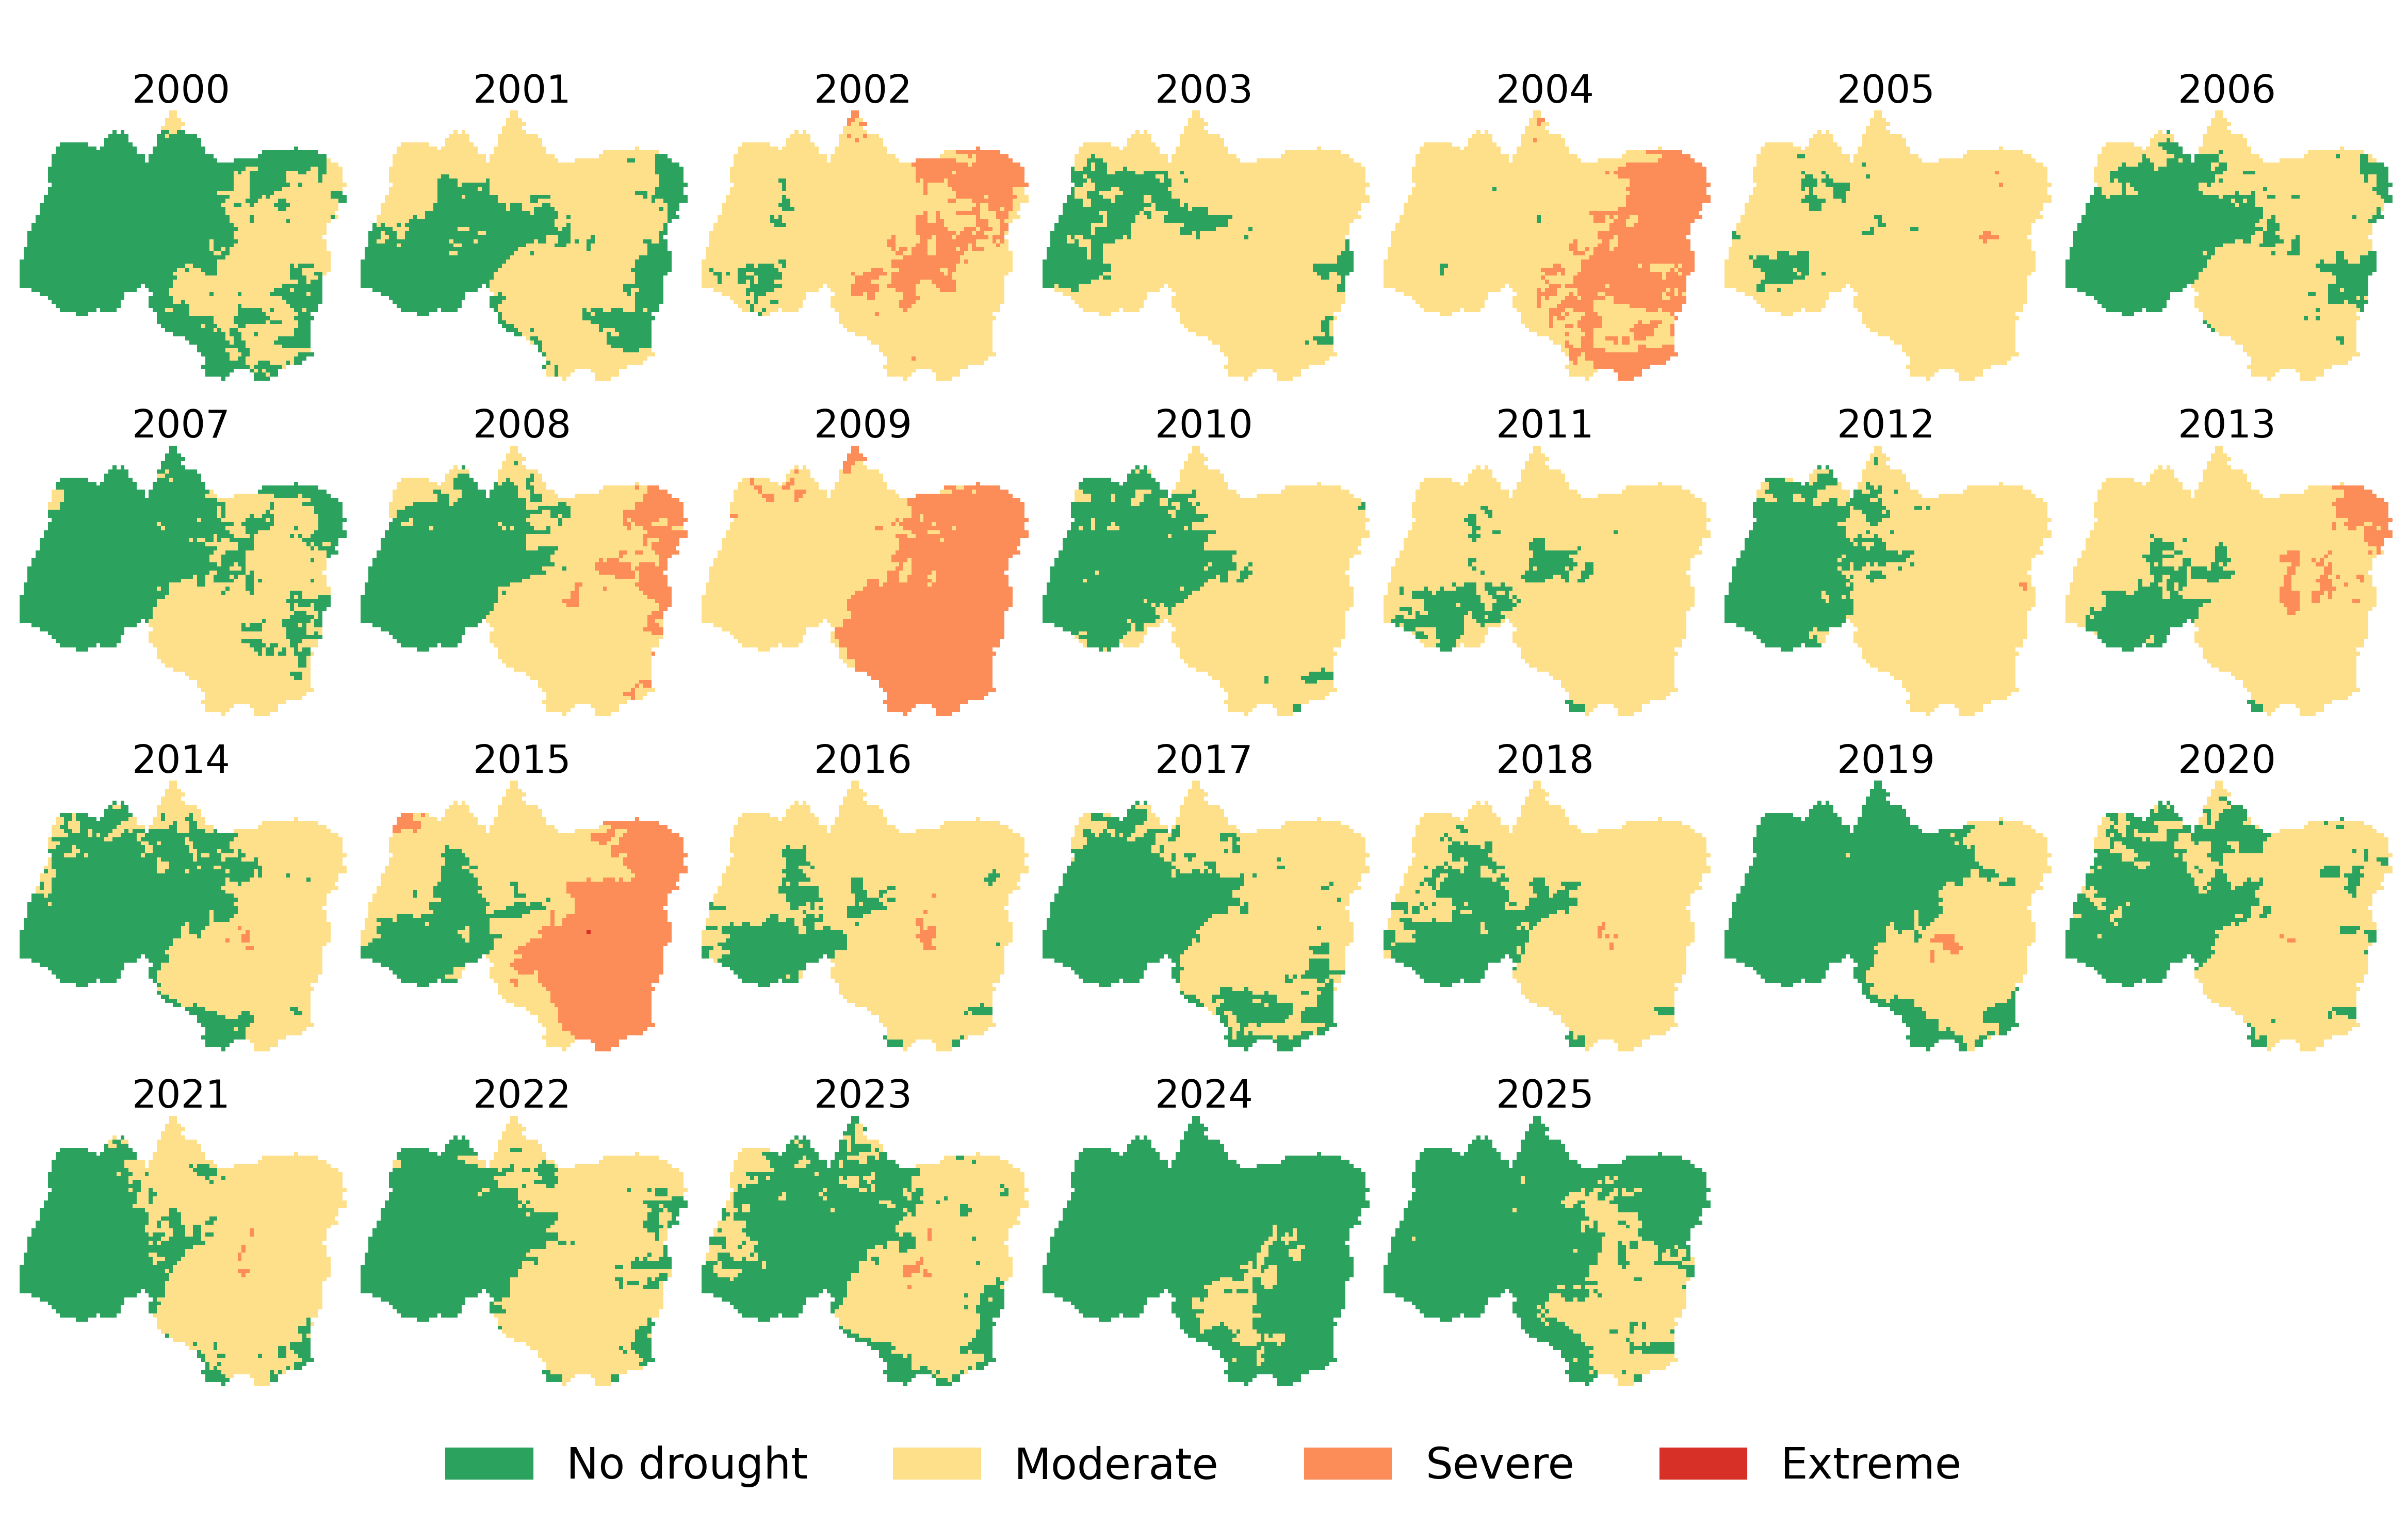

DONE ✔ Saved: CDI_26panel_clean_grid_2000_2025_2.png


In [2]:
import os
import numpy as np
import rasterio
import glob
import matplotlib.pyplot as plt
from collections import defaultdict
from matplotlib.colors import ListedColormap, BoundaryNorm
from rasterio.plot import show
import matplotlib.patches as mpatches

# ============================================================
# STYLE SETTINGS (clean publication look)
# ============================================================

plt.rcParams.update({
    "font.size": 8,
    "axes.titlesize": 9
})

# ============================================================
# INPUT
# ============================================================

folder = r"C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT_CLIPPED"
files = sorted(glob.glob(os.path.join(folder, "CDI_*.tif")))

# ============================================================
# GROUP BY YEAR
# ============================================================

year_files = defaultdict(list)

for f in files:
    name = os.path.basename(f)
    y, m = name.replace("CDI_", "").replace(".tif", "").split("_")
    year_files[int(y)].append((int(m), f))

for y in year_files:
    year_files[y] = sorted(year_files[y], key=lambda x: x[0])

years = sorted(year_files.keys())

# ============================================================
# CLASSIFICATION
# ============================================================

def classify(arr):
    cls = np.full(arr.shape, np.nan)

    cls[(arr > -0.5)] = 1
    cls[(arr <= -0.5) & (arr > -1.0)] = 2
    cls[(arr <= -1.0) & (arr > -1.5)] = 3
    cls[(arr <= -1.5)] = 4

    return cls

# ============================================================
# COLOR MAP
# ============================================================

colors = ["#2ca25f", "#fee08b", "#fc8d59", "#d73027"]
cmap = ListedColormap(colors)
norm = BoundaryNorm([1, 2, 3, 4, 5], cmap.N)

# ============================================================
# FIGURE (SMALL BUT NOT TOUCHING)
# ============================================================

nrows, ncols = 4, 7

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, 10),
    dpi=300
)

axes = axes.flatten()

# ============================================================
# PLOT EACH YEAR
# ============================================================

for i, year in enumerate(years):

    stack = []
    meta = None

    for m, f in year_files[year]:
        with rasterio.open(f) as src:
            arr = src.read(1).astype("float32")

            if src.nodata is not None:
                arr[arr == src.nodata] = np.nan

            stack.append(arr)

            if meta is None:
                meta = src

    yearly = np.nanmean(stack, axis=0)
    classified = classify(yearly)

    ax = axes[i]

    show(
        classified,
        ax=ax,
        cmap=cmap,
        norm=norm,
        transform=meta.transform
    )

    # ========================================================
    # CLEAN MAP LOOK (NO LAT/LON GRID OR AXES)
    # ========================================================

    ax.set_title(str(year), fontsize=18, pad=3)

    ax.set_xticks([])
    ax.set_yticks([])

    # remove borders/spines
    for spine in ax.spines.values():
        spine.set_visible(False)

# turn off empty panels
for j in range(len(years), len(axes)):
    axes[j].axis("off")

# ============================================================
# TITLE
# ============================================================

fig.suptitle(
    " ",
    fontsize=17,
    y=0.98
)
# Annual Agricultural Drought Classification (CDI, 2000–2025)
# ============================================================
# LEGEND
# ============================================================

legend_patches = [
    mpatches.Patch(color=colors[0], label="No drought"),
    mpatches.Patch(color=colors[1], label="Moderate"),
    mpatches.Patch(color=colors[2], label="Severe"),
    mpatches.Patch(color=colors[3], label="Extreme")
]

fig.legend(
    handles=legend_patches,
    loc="lower center",
    ncol=4,
    frameon=False,
    fontsize=20
)

# ============================================================
# CONTROL GAPS (THIS IS THE KEY FIX)
# ============================================================

plt.subplots_adjust(
    left=0.02,
    right=0.98,
    top=0.93,
    bottom=0.08,
    wspace=0.03,   # 👈 small horizontal gap (NOT zero)
    hspace=0.08    # 👈 small vertical gap for titles
)

# ============================================================
# SAVE HIGH QUALITY OUTPUT
# ============================================================

output = "CDI_26panel_clean_grid_2000_2025_2.png"

plt.savefig(output, dpi=600, bbox_inches="tight")

plt.show()

print("DONE ✔ Saved:", output)

In [13]:
import os
import numpy as np
import rasterio
import glob
import pandas as pd
from collections import defaultdict

# ============================================================
# INPUT
# ============================================================

folder = r"C:\Users\gerii\Documents\projects\tekeze\indices\CDI_OUTPUT_CLIPPED"
files = sorted(glob.glob(os.path.join(folder, "CDI_*.tif")))

# ============================================================
# GROUP BY YEAR
# ============================================================

year_files = defaultdict(list)

for f in files:
    name = os.path.basename(f)
    y, m = name.replace("CDI_", "").replace(".tif", "").split("_")
    year_files[int(y)].append(f)

years = sorted(year_files.keys())

# ============================================================
# STORAGE
# ============================================================

results = []

# ============================================================
# LOOP YEARS
# ============================================================

for year in years:

    stack = []
    meta = None

    for f in year_files[year]:
        with rasterio.open(f) as src:
            arr = src.read(1).astype("float32")

            if src.nodata is not None:
                arr[arr == src.nodata] = np.nan

            stack.append(arr)

            if meta is None:
                meta = src

    yearly = np.nanmean(stack, axis=0)

    valid = ~np.isnan(yearly)
    total_pixels = np.sum(valid)

    # ========================================================
    # CONSISTENT WITH YOUR CLASSIFICATION
    # ========================================================

    # CLASS 1 ONLY (NO DROUGHT)
    no_drought = (yearly > -0.5) & valid

    # CLASS 2 + 3 + 4 (ALL DROUGHT)
    drought = (yearly <= -0.5) & valid

    no_drought_pct = (np.sum(no_drought) / total_pixels) * 100
    drought_pct = (np.sum(drought) / total_pixels) * 100

    results.append([year, drought_pct, no_drought_pct])

# ============================================================
# DATAFRAME
# ============================================================

df = pd.DataFrame(results, columns=[
    "Year", "Drought_Area_%", "NoDrought_Area_%"
])

print(df)

# ============================================================
# SAVE CSV (INPUT FOLDER)
# ============================================================

csv_path = os.path.join(folder, "CDI_yearly_drought_area_corrected.csv")
df.to_csv(csv_path, index=False)

print("✔ Saved CSV:", csv_path)

# ============================================================
# AUTOMATIC PARAGRAPH
# ============================================================

paragraph = "\nRESULTS SUMMARY:\n\n"

for _, row in df.iterrows():
    paragraph += (
        f"In {int(row['Year'])}, "
        f"{row['Drought_Area_%']:.2f}% of the Tekeze Basin experienced agricultural drought conditions "
        f"(CDI ≤ -0.5), while {row['NoDrought_Area_%']:.2f}% remained under non-drought conditions. "
    )

paragraph += (
    "\n\nOverall, the results based on CDI classification reveal clear interannual variability in drought extent, "
    "with frequent expansion of drought-affected areas during dry years and contraction during wetter years, "
    "highlighting strong hydroclimatic sensitivity of the Tekeze Basin."
)

# ============================================================
# SAVE PARAGRAPH
# ============================================================

txt_path = os.path.join(folder, "CDI_yearly_drought_results.txt")

with open(txt_path, "w", encoding="utf-8") as f:
    f.write(paragraph)

print("✔ Saved paragraph:", txt_path)

print("\nDONE ✔ All outputs saved in input folder.")

C:\Users\geri geri\AppData\Local\Temp\ipykernel_8296\3561910357.py:55: RuntimeWarning: Mean of empty slice
  yearly = np.nanmean(stack, axis=0)


    Year  Drought_Area_%  NoDrought_Area_%
0   2000       30.818713         69.181287
1   2001       60.877193         39.122807
2   2002       97.076023          2.923977
3   2003       80.730994         19.269006
4   2004       99.795322          0.204678
5   2005       95.321637          4.678363
6   2006       57.192982         42.807018
7   2007       42.865497         57.134503
8   2008       61.491228         38.508772
9   2009      100.000000          0.000000
10  2010       62.309942         37.690058
11  2011       88.742690         11.257310
12  2012       66.666667         33.333333
13  2013       87.192982         12.807018
14  2014       50.555556         49.444444
15  2015       82.163743         17.836257
16  2016       83.362573         16.637427
17  2017       53.216374         46.783626
18  2018       76.491228         23.508772
19  2019       38.742690         61.257310
20  2020       58.859649         41.140351
21  2021       61.871345         38.128655
22  2022   